<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QML_UAVSwarmIntrusion_Chen2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum kernel, QNN, hybrid QNN and quantum-trained NN for UAV-swarm intrusion detection: Chen et al. (2025) step by step

This notebook re-implements, runs and checks the experiment of

> Kuan-Cheng Chen, Samuel Yen-Chi Chen, Tai-Yue Li, Chen-Yu Liu and Kin K. Leung, "Quantum Machine Learning for UAV Swarm
> Intrusion Detection", *IEEE Globecom 2025 Workshops*, 2025. arXiv:2509.01812.
> DOI 10.1109/GCWKSHPS68340.2025.11590964

The paper's own code (`cuTN-QSVM`, a tensor-network simulator) is not needed here: all circuits have 7 to 9 qubits and are
simulated exactly. Everything below is written from the four-page description.

**What the notebook does.** It downloads the real **UAVIDS-2025** corpus (122,171 flows of an NS-3 UAV-swarm simulation:
Normal, Blackhole, Flooding, Sybil, Wormhole; Zenodo record 15336998, mirrored on GitHub), builds the paper's
8-dimensional flow representation, and trains on a class-balanced subset the same families of models as the paper's Table I:
a classical SVM, a **quantum-kernel SVM** (8 qubits), **pure variational QNNs** with 6, 8 and 10 layers, **hybrid QNNs** with
2 to 10 layers and a tiny classical read-out head, and **quantum-trained neural networks** (QT-NN) in which a small
circuit generates the weights of a classical network. Models are tested on a held-out split that keeps the dataset's natural
class mix (about 79 % attacks), which is what the paper's accuracy / specificity / sensitivity columns imply.
Classical baselines (SVM RBF, random forest, MLP) get exactly the same inputs. The last section prints the paper's Table I
next to our numbers with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. `FAST_MODE = True` (600 training flows, 1 seed) finishes in about 10 to 15 minutes on a laptop; `FAST_MODE = False` (the setting of the saved outputs: 3,000 training flows, three seeds, longer training, about 80 minutes on a busy 4-core CPU) is set in the configuration cell. No GPU, no account and no token is needed: the dataset is
public on Zenodo (it is **not** a Hugging Face dataset, so no `HF_TOKEN` is required).

**What you get at the end.** The dataset exploration (class distribution, labelled 2-D scatter plots), the drawn circuits
with qubit / depth / parameter counts, Table I re-computed (mean and standard deviation over seeds), confusion matrices,
training curves, a per-attack-type breakdown and a verdict per claim of the paper.

## The paper in one page

**Problem.** Flow-level intrusion detection in a UAV swarm (a flying ad-hoc network) with strong class imbalance and
mobility. The reported task is **binary** (Table I: "Binary-IDS performance"): normal flow versus attack flow, with the
attack as the positive class (sensitivity = attack recall, specificity = normal recall).

**Data.** UAVIDS-2025 (Zeng, Bashir, Nait-Abdesselam, IEEE CNS 2025): NS-3.24, extended BOID mobility, Nakagami channel,
IEEE 802.11ac, AODV routing; 122,171 labelled flows, five classes (Normal, Blackhole, Flooding, Sybil, Wormhole).

**Features.** Eight engineered flow features (duration, packet rate, byte rate, mean packet size, coefficient of variation
of inter-arrival times, directional asymmetry ratio, short-term jitter, peak-to-mean burst ratio); the rate features are
passed through $\log(1+x)$; all features are standardised with training statistics only.

**Models (Table I).**
* classical SVM and **quantum kernel** (8 qubits; the kernel is $K(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2$, Eq. 5);
* **QNN-6L / 8L / 10L**: 8 qubits, 6 / 8 / 10 layers, 0 classical and 48 / 64 / 80 quantum parameters (8 per layer);
* **HybridQNN-2L ... 10L**: the same circuit family with a classical head of **18 parameters** (a linear map from the 8
  Pauli-Z expectations to 2 logits: $8\cdot2+2=18$) and 16 / 32 / 48 / 64 / 80 quantum parameters;
* **QT-NN (h, L)**: a circuit with 7 / 8 / 9 qubits and $L$ layers that is *not* fed the data. Its basis-state probabilities
  $g(\theta)$ are mapped to the 66 / 162 / 450 weights of a classical network $8\to h\to h\to2$ ($8h+h+h^2+h+2h+2$ =
  66, 162, 450 for $h$ = 4, 8, 16), so the only trainable parameters are the 14-36 circuit angles (Eq. 13-14).

**Reported results (Table I).** Accuracy / F1 / specificity / sensitivity, e.g. SVM 0.924 / 0.951 / 0.836 / 0.947;
quantum kernel 0.926 / 0.956 / 0.728 / 0.981; deep QNNs about 0.80 with specificity 0.04-0.23; HybridQNN-8L the best
(0.948 / 0.967 / 0.838 / 0.972); QT-NN about 0.94 except two configurations that predict "attack" for every flow
(0.786 / 0.879 / 0.000 / 1.000).

**A useful sanity check.** Solving "accuracy = sensitivity $a$ + specificity $(1-a)$" for the rows of Table I gives
$a\approx0.786$, which is exactly the attack share of the full dataset (96,000 / 122,171 = 78.6 %). The paper's test set therefore
keeps the **natural class mix**, while the training set is a "balanced subset". The notebook follows that protocol.

## What follows the paper and what had to be chosen

The paper does not publish training-set size, optimiser, learning rate, number of steps, encoding of the QNNs, kernel
bandwidth, the exact mapping $T$ of the QT-NN, or the raw-to-feature code. The table lists every choice; each is marked
`# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | UAVIDS-2025, 122,171 flows, 5 classes | the same file (Zenodo 15336998, md5 checked), downloaded in the notebook |
| Task | binary IDS, attack positive (Table I) | binary, attack = 1; 5-class labels kept for plots and a per-attack breakdown |
| Features | 8 features computed from 22 raw attributes | the released CSV has **21 flow statistics but no per-packet timestamps or directional byte counts**, so features 5, 6 and 8 are **proxies** (see section 2) |
| Standardisation | training statistics only | `StandardScaler` fitted on the training split; then clipped to $\pm3$ and mapped to $[0,\pi]$ as rotation angles (CHOICE) |
| Train / test | "balanced subset", test mix implied natural | stratified 80 / 20 split of the whole file; training = class-balanced subset (`N_TRAIN` flows, half normal / half attack); test = the whole 20 % split (natural mix, about 79 % attacks) |
| Quantum kernel | 8 qubits, cuTN-QSVM, feature map not stated | Qiskit `zz_feature_map(8, reps=2, linear)` computed exactly; bandwidth and $C$ picked on a validation part of the training set |
| QNN | 8 qubits, L layers, 8L parameters | RY angle encoding, then L x [RY(theta) on every qubit + ring of CNOTs]; read-out $\langle Z_0\rangle$ (CHOICE) |
| HybridQNN | + 18 classical parameters | same circuit; read-out $\langle Z_j\rangle$ for all 8 qubits -> `Linear(8, 2)` (8x2+2 = 18 parameters) |
| QT-NN | 66 / 162 / 450 generated weights | MLP $8\to h\to h\to2$ (ReLU); weights = per-tensor standardised basis-state probabilities of the circuit, scaled by $1/\sqrt{\text{fan-in}}$ (CHOICE for $T$) |
| Optimiser | not stated | Adam, learning rate 0.05, mini-batches, cross-entropy, no early stopping (CHOICE) |
| Simulation | tensor-network simulator, also noise / shots | exact noise-free statevector simulation in PyTorch, asserted equal to PennyLane / Qiskit circuits; shot noise is not part of Table I and is not reproduced |
| Seeds | not stated | `SEED = 42`; `N_SEEDS` different splits / initialisations, mean +- std |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever Qiskit / PennyLane are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("pennylane") is None:
    %pip install -q "qiskit==2.5.2" "pennylane==0.45.1" pylatexenc
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit and pennylane already present; skipping pip install.")

qiskit and pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False      # True: class demo (600 training flows, 1 seed, 100 steps), a few minutes.
                        # False: 4,000 training flows, 3 seeds, 600 steps per variational model.
SEED      = 42          # CHOICE: the paper does not give a seed
N_QUBITS  = 8           # paper: 8 features -> 8 qubits (QT-NN uses 7/8/9 qubits for its weight generator)
TEST_SIZE = 0.20        # CHOICE: stratified 80 / 20 split of the whole file; the test part keeps the natural class mix

if FAST_MODE:
    N_TRAIN = 600       # CHOICE: class-balanced training flows (half normal, half attack)
    N_SEEDS = 1
    STEPS   = 100       # Adam steps for QNN / HybridQNN (QT-NN gets QT_STEPS_FACTOR times more)
    BATCH   = 128
else:
    N_TRAIN = 3000      # CHOICE: the paper only says "balanced subset"
    N_SEEDS = 3
    STEPS   = 250
    BATCH   = 128

QT_STEPS_FACTOR = 3                  # CHOICE: QT-NN steps are ~20x cheaper (one circuit per step, no data encoding), so they train 3x longer
LR            = 0.05                 # CHOICE: Adam learning rate (not stated in the paper)
KERNEL_REPS   = 2                    # CHOICE: zz_feature_map repetitions
ENTANGLEMENT  = "linear"             # CHOICE: nearest-neighbour ZZ pairs
BANDWIDTHS    = [0.25, 0.5, 1.0]     # CHOICE: candidate angle scales gamma of the quantum kernel (picked on a validation split)
C_GRID        = [1.0, 10.0]          # CHOICE: SVM regularisation candidates (picked on the same validation split)
RBF_GAMMAS    = ["scale", 0.3, 1.0]  # CHOICE: RBF bandwidth candidates of the classical SVM
VAL_FRACTION  = 0.25                 # inner validation part of the (balanced) training subset
CLIP_Z        = 3.0                  # CHOICE: standardised features are clipped to +-3 before the map to [0, pi]
DATA_DIR      = "uavids_data"        # downloaded CSV is cached here
CSV_PATH      = ""                   # optional: path of an uploaded UAVIDS-2025.csv (skips the download)
IBM_TOKEN     = ""                   # real hardware is not used by the paper's Table I; kept for API symmetry
TOL_ACC, TOL_F1, TOL_SS = 0.02, 0.02, 0.05   # "reproduced" tolerances (accuracy, F1, specificity / sensitivity)

In [3]:
import os, time, math, hashlib, warnings, functools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import torch, torch.nn as nn, torch.nn.functional as F
torch.set_default_dtype(torch.float64)
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, matthews_corrcoef, roc_auc_score,
                             precision_score, ConfusionMatrixDisplay)

import qiskit, pennylane as qml
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector

np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
print("qiskit", qiskit.__version__, "| pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN =", N_TRAIN, "| seeds =", N_SEEDS, "| steps =", STEPS)

qiskit 2.5.2 | pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4
FAST_MODE = False | N_TRAIN = 3000 | seeds = 3 | steps = 250


## 1. The UAVIDS-2025 dataset

UAVIDS-2025 was produced by the NS-3.24 network simulator: a swarm of UAVs moves with an extended BOID flocking model,
talks over IEEE 802.11ac with AODV routing through a Nakagami fading channel, and four network-layer attacks are
injected (**Blackhole**: a node silently drops forwarded packets; **Flooding**: a node saturates the network;
**Sybil**: a node forges several identities; **Wormhole**: two colluding nodes tunnel traffic). Every row is one flow
(source, destination, port) with 21 measured statistics and a label. The file is public on Zenodo
(record 15336998, `UAVIDS-2025.csv`, 20 MB, CC licence) and on GitHub (`QingliZeng/UAV--IDS2025`). The dataset is itself
**simulated**; it is the paper's own data, so nothing here is generated or invented by this notebook.

The cell below downloads the file (resumable, checked by size and MD5), with the GitHub copy as a fallback, or reads the
file you uploaded (`CSV_PATH`).

In [4]:
import requests
ZENODO_URL = "https://zenodo.org/api/records/15336998/files/UAVIDS-2025.csv/content"
GITHUB_URL = "https://raw.githubusercontent.com/QingliZeng/UAV--IDS2025/HEAD/data/UAVIDS-2025.csv"
EXPECTED_BYTES, EXPECTED_MD5 = 20054667, "ec84ed5390d5de42b07e8a011709ff82"

def download(url, path, retries=12):
    # resumable download: keep what is on disk and ask for the rest with a Range header
    for attempt in range(retries):
        have = os.path.getsize(path) if os.path.exists(path) else 0
        if have >= EXPECTED_BYTES:
            return True
        try:
            headers = {"Range": f"bytes={have}-"} if have else {}
            with requests.get(url, headers=headers, stream=True, timeout=60) as r:
                if r.status_code not in (200, 206):
                    raise RuntimeError(f"HTTP {r.status_code}")
                mode = "ab" if (have and r.status_code == 206) else "wb"
                with open(path, mode) as fh:
                    for chunk in r.iter_content(1 << 16):
                        fh.write(chunk)
        except Exception as e:
            print(f"  attempt {attempt + 1} on {url.split('/')[2]}: {type(e).__name__}: {str(e)[:80]}")
    return os.path.exists(path) and os.path.getsize(path) >= EXPECTED_BYTES

def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for b in iter(lambda: fh.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

if CSV_PATH:
    csv = CSV_PATH
else:
    csv = os.path.join(DATA_DIR, "UAVIDS-2025.csv")
    for url in (ZENODO_URL, GITHUB_URL):
        if download(url, csv):
            break
        if os.path.exists(csv):
            os.remove(csv)       # corrupt / partial: start over with the next mirror
    if not os.path.exists(csv):
        raise RuntimeError("UAVIDS-2025.csv could not be downloaded; upload it and set CSV_PATH")
print("file:", csv, "|", os.path.getsize(csv), "bytes | md5 ok:", md5_of(csv) == EXPECTED_MD5)
raw = pd.read_csv(csv)
print("raw shape:", raw.shape)

file: uavids_data\UAVIDS-2025.csv | 20054667 bytes | md5 ok: True


raw shape: (122171, 23)


## 2. The paper's 8 features, binary labels and the split

The paper describes eight features. Five can be computed from the released CSV directly or almost directly; three need
per-packet information (inter-arrival times, forward / backward byte counts, sliding-window byte rates) that the CSV does
not contain, so **proxies from the available flow statistics** are used and flagged:

| # | Paper feature | Computed here from the CSV | Exact? |
|---|---|---|---|
| 1 | flow duration $T$ | `FlowDuration/s` | yes |
| 2 | packet rate $r_p$, $\log(1+x)$ | `TxPacketRate/s` | yes |
| 3 | byte rate $r_b$, $\log(1+x)$ | `TxByteRate/s` | yes |
| 4 | mean packet size | `MeanPacketSize` | yes |
| 5 | inter-arrival dispersion $CV_{\Delta t}$ | `MeanJitter/s / MeanDelay/s` (jitter relative to delay) | **proxy** |
| 6 | directional asymmetry ratio | `(TxBytes - RxBytes) / (TxBytes + RxBytes + eps)` (sent vs received share) | **proxy** |
| 7 | short-term jitter | `MeanJitter/s` | close |
| 8 | peak-to-mean burst ratio, $\log(1+x)$ | `TxByteRate / (RxByteRate + eps)` capped at 1000 (offered vs delivered rate) | **proxy** |

Identifiers (flow id, IP addresses, ports) are not used. The label is binary for training and testing
(Normal = 0, any attack = 1) while the five-class label is kept for the plots and for a per-attack breakdown.

**Protocol.** One stratified 80 / 20 split of the whole file (by five-class label); all transforms are fitted on the 80 %
part; the training set is a class-balanced random subset of `N_TRAIN` flows of that part (half normal, half attacks drawn
at random, so the attack types appear in their natural proportions); the model is tested on the entire 20 % part (about
24,000 flows, 78.6 % attacks). Features are standardised (training statistics), clipped to $\pm3$ standard deviations and
mapped linearly to $[0,\pi]$ so they can be used as rotation angles; **the classical baselines receive these same angles**.

In [5]:
CLASS_NAMES = ["Normal Traffic", "Blackhole Attack", "Wormhole Attack", "Sybil Attack", "Flooding Attack"]
SHORT = {"Normal Traffic": "Normal", "Blackhole Attack": "Blackhole", "Wormhole Attack": "Wormhole",
         "Sybil Attack": "Sybil", "Flooding Attack": "Flooding"}
FEATURE_NAMES = ["flow_duration", "log_packet_rate", "log_byte_rate", "mean_packet_size",
                 "cv_proxy", "dar_proxy", "jitter", "log_burst_proxy"]
PALETTE = {"Normal": "#2b8cbe", "Blackhole": "#d95f02", "Wormhole": "#7570b3", "Sybil": "#1b9e77", "Flooding": "#e7298a"}

def build_features(df, eps=1e-9):
    f = pd.DataFrame(index=df.index)
    f["flow_duration"]    = df["FlowDuration/s"]
    f["log_packet_rate"]  = np.log1p(df["TxPacketRate/s"])
    f["log_byte_rate"]    = np.log1p(df["TxByteRate/s"])
    f["mean_packet_size"] = df["MeanPacketSize"]
    f["cv_proxy"]         = (df["MeanJitter/s"] / (df["MeanDelay/s"] + eps)).clip(0, 1e3)       # CHOICE (proxy)
    f["dar_proxy"]        = (df["TxBytes"] - df["RxBytes"]) / (df["TxBytes"] + df["RxBytes"] + eps)  # CHOICE (proxy)
    f["jitter"]           = df["MeanJitter/s"]
    f["log_burst_proxy"]  = np.log1p((df["TxByteRate/s"] / (df["RxByteRate/s"] + eps)).clip(0, 1e3))  # CHOICE (proxy)
    return f

df = raw.copy()          # CHOICE: keep every flow (the paper counts 122,171)
df.columns = [c.strip() for c in df.columns]
FEAT = build_features(df)
assert np.isfinite(FEAT.to_numpy()).all(), "non-finite feature values"
lab5 = df["label"].map({c: i for i, c in enumerate(CLASS_NAMES)}).to_numpy()
assert not np.isnan(lab5.astype(float)).any()
y_bin = (lab5 != 0).astype(int)              # attack = 1 (positive class)
print("features:", FEAT.shape, "| attack share:", round(y_bin.mean(), 4))
display(FEAT.describe().T[["mean", "std", "min", "50%", "max"]])

features: (122171, 8) | attack share: 0.7858


,mean,std,min,50%,max
flow_duration,696.714475,780.052068,0.000076,227.867000,10591.800000
log_packet_rate,0.531819,0.659240,0.001196,0.186665,10.407820
log_byte_rate,3.012235,1.858792,0.043704,2.695681,14.738523
mean_packet_size,68.122885,13.838427,30.000000,76.000000,76.000000
cv_proxy,0.837222,0.459199,0.000000,0.871068,1.999635
dar_proxy,0.283609,0.277098,0.000000,0.178218,1.000000
jitter,0.140080,0.306921,0.000000,0.043962,6.717600
log_burst_proxy,1.173415,0.689300,0.693147,0.889427,6.908755


In [6]:
from types import SimpleNamespace
def to_angles(Z):
    # CHOICE: clip standardised features to +-CLIP_Z and map linearly to [0, pi]
    return np.pi * (np.clip(Z, -CLIP_Z, CLIP_Z) + CLIP_Z) / (2 * CLIP_Z)

def make_split(seed):
    idx = np.arange(len(FEAT))
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=lab5, random_state=seed)
    scaler = StandardScaler().fit(FEAT.values[tr])                 # fitted on the training split only
    Z_tr, Z_te = scaler.transform(FEAT.values[tr]), scaler.transform(FEAT.values[te])
    rng = np.random.default_rng(seed)
    normal, attack = tr[y_bin[tr] == 0], tr[y_bin[tr] == 1]
    sub = np.concatenate([rng.choice(normal, N_TRAIN // 2, replace=False), rng.choice(attack, N_TRAIN // 2, replace=False)])
    rng.shuffle(sub)
    pos = {g: i for i, g in enumerate(tr)}
    sub_pos = np.array([pos[g] for g in sub])
    return SimpleNamespace(seed=seed, tr=tr, te=te, scaler=scaler, Z_tr=Z_tr, Z_te=Z_te,
                           Z_sub=Z_tr[sub_pos], A_sub=to_angles(Z_tr[sub_pos]), y_sub=y_bin[sub], lab_sub=lab5[sub],
                           A_te=to_angles(Z_te), y_te=y_bin[te], lab_te=lab5[te])

S0 = make_split(SEED)
print(f"split (seed {SEED}): train part {len(S0.tr)} flows, test part {len(S0.te)} flows (attack share {S0.y_te.mean():.3f})")
print(f"balanced training subset: {len(S0.y_sub)} flows, attack share {S0.y_sub.mean():.2f}; "
      f"classes {dict(zip([SHORT[c] for c in CLASS_NAMES], np.bincount(S0.lab_sub, minlength=5).tolist()))}")
print("trivial 'always attack' accuracy on the test part:", round(S0.y_te.mean(), 4), "(the paper's QT-NN collapses sit exactly here: 0.786)")

split (seed 42): train part 97736 flows, test part 24435 flows (attack share 0.786)
balanced training subset: 3000 flows, attack share 0.50; classes {'Normal': 1500, 'Blackhole': 416, 'Wormhole': 380, 'Sybil': 384, 'Flooding': 320}
trivial 'always attack' accuracy on the test part: 0.7858 (the paper's QT-NN collapses sit exactly here: 0.786)


## Dataset Exploration and Visualisation

This section looks at the real UAVIDS-2025 flows before any model is trained: shape, columns, the original label values
with their counts, the class distribution, and 2-D scatter plots in which **every point is a real flow coloured by its
ground-truth class** (all five classes are kept, not only normal / attack). The PCA is fitted on the training split only;
the second plot shows the same coordinates scaled to $[0,\pi]$ (the range of a rotation angle), and the third shows
two of the eight actual rotation angles that go into the circuits.

raw dataset shape: (122171, 23)
columns (23): ['FlowID', 'FlowDuration/s', 'SrcAddr', 'SrcPort', 'DstAddr', 'DstPort', 'Protocol', 'TxPackets', 'RxPackets', 'LostPackets', 'TxBytes', 'RxBytes', 'TxPacketRate/s', 'RxPacketRate/s', 'TxByteRate/s', 'RxByteRate/s', 'MeanDelay/s', 'MeanJitter/s', 'Throughput/Kbps', 'MeanPacketSize', 'PacketDropRate', 'AverageHopCount', 'label']

original label values and counts:


,flows,share
label,,
Normal Traffic,26172,0.2142
Blackhole Attack,26110,0.2137
Wormhole Attack,26086,0.2135
Sybil Attack,24077,0.1971
Flooding Attack,19726,0.1615


binary view: Normal = 26172 | attack (4 types) = 95999

the 8 model features: ['flow_duration', 'log_packet_rate', 'log_byte_rate', 'mean_packet_size', 'cv_proxy', 'dar_proxy', 'jitter', 'log_burst_proxy']


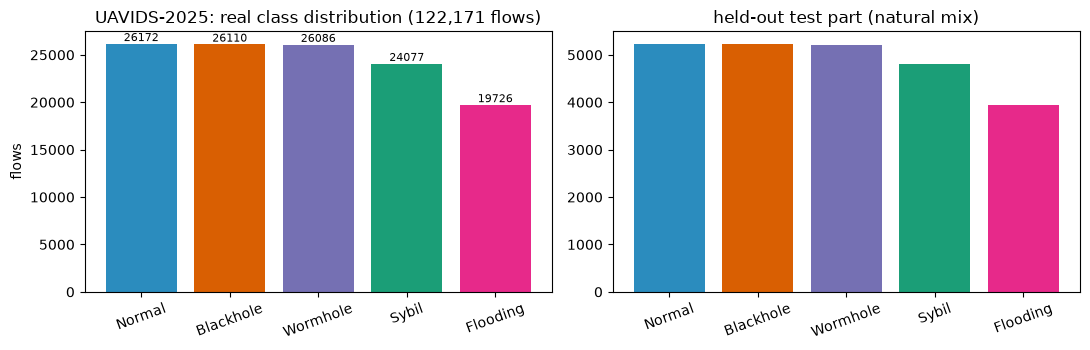

In [7]:
print("raw dataset shape:", raw.shape)
print("columns (%d):" % raw.shape[1], list(raw.columns))
print("\noriginal label values and counts:")
vc = raw["label"].value_counts()
display(vc.to_frame("flows").assign(share=lambda d: (d.flows / d.flows.sum()).round(4)))
print("binary view: Normal =", int((y_bin == 0).sum()), "| attack (4 types) =", int((y_bin == 1).sum()))
print("\nthe 8 model features:", FEATURE_NAMES)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
names = [SHORT[c] for c in vc.index]
ax[0].bar(names, vc.values, color=[PALETTE[n] for n in names]); ax[0].set_title("UAVIDS-2025: real class distribution (122,171 flows)")
ax[0].set_ylabel("flows"); ax[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(vc.values): ax[0].text(i, v, str(v), ha="center", va="bottom", fontsize=8)
bt = np.bincount(S0.lab_te, minlength=5)
ax[1].bar([SHORT[c] for c in CLASS_NAMES], bt, color=[PALETTE[SHORT[c]] for c in CLASS_NAMES])
ax[1].set_title("held-out test part (natural mix)"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

explained variance of the 2 PCA axes: [0.3   0.276]


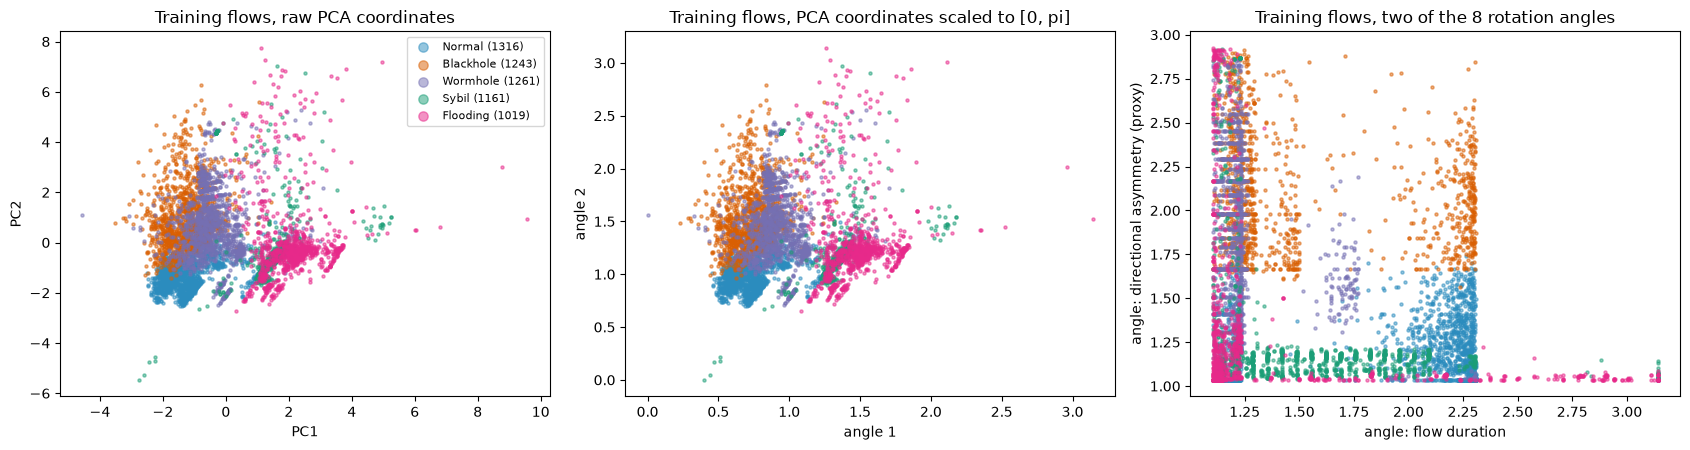

The attack families overlap strongly in the first two PCA axes; the models use all eight angles, not these two.


In [8]:
# PCA fitted on the training split (standardised features); points are real test-free training flows, class-coloured
rng_v = np.random.default_rng(SEED)
vis = rng_v.choice(len(S0.Z_tr), 6000, replace=False)
pca = PCA(n_components=2, random_state=SEED).fit(S0.Z_tr)
P = pca.transform(S0.Z_tr[vis]); labv = lab5[S0.tr][vis]
print("explained variance of the 2 PCA axes:", pca.explained_variance_ratio_.round(3))

def scatter(ax, XY, labs, title, xl, yl):
    for k, c in enumerate(CLASS_NAMES):
        m = labs == k
        ax.scatter(XY[m, 0], XY[m, 1], s=5, alpha=0.5, color=PALETTE[SHORT[c]], label=f"{SHORT[c]} ({m.sum()})")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
scatter(axes[0], P, labv, "Training flows, raw PCA coordinates", "PC1", "PC2")
lo, hi = P.min(0), P.max(0)
Ps = np.pi * (P - lo) / (hi - lo)       # same coordinates mapped to [0, pi] (min-max fitted on the plotted training flows)
scatter(axes[1], Ps, labv, "Training flows, PCA coordinates scaled to [0, pi]", "angle 1", "angle 2")
Av = to_angles(S0.Z_tr[vis])
scatter(axes[2], Av[:, [0, 5]], labv, "Training flows, two of the 8 rotation angles", "angle: flow duration", "angle: directional asymmetry (proxy)")
axes[0].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()
print("The attack families overlap strongly in the first two PCA axes; the models use all eight angles, not these two.")

## 3. Metrics and the classical baselines

Metrics follow Table I of the paper: accuracy, F1 of the attack class, specificity (recall of normal flows) and
sensitivity (recall of attacks); we add precision, macro-F1, ROC-AUC and the Matthews correlation coefficient that the
abstract mentions. Because the test part is 78.6 % attacks, an all-attack classifier has accuracy 0.786, F1 0.879,
specificity 0 and sensitivity 1; that row is the "no skill" reference.

Baselines on the identical balanced training subset and the identical 8 angle features: an RBF **SVM** (the paper's classical
baseline; $C$ and $\gamma$ picked on an inner validation split of the training subset), a random forest and a small MLP.
The SVM is also run on the unclipped standardised features (the paper's "standardised" input).

In [9]:
def metrics(y, pred, score):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(acc=(tp + tn) / len(y), f1=f1_score(y, pred, zero_division=0), spec=tn / max(tn + fp, 1), sens=tp / max(tp + fn, 1),
                prec=precision_score(y, pred, zero_division=0), macro_f1=f1_score(y, pred, average="macro", zero_division=0),
                mcc=matthews_corrcoef(y, pred), auc=roc_auc_score(y, score) if len(np.unique(score)) > 1 else 0.5,
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def per_class_recall(lab, pred):
    # recall by true five-class label: for Normal it is the specificity, for the attacks the per-attack sensitivity
    return {SHORT[CLASS_NAMES[k]]: float(((pred == (0 if k == 0 else 1)) & (lab == k)).sum() / max((lab == k).sum(), 1)) for k in range(5)}

RESULTS = []      # one dict per (model, seed)
CURVES = {}       # training losses of seed 0
def record(name, S, pred, score, seconds, qparams=0, cparams=0, extra=None):
    row = dict(model=name, seed=S.seed, seconds=seconds, qparams=qparams, cparams=cparams, **metrics(S.y_te, pred, score))
    row.update({"rec_" + k: v for k, v in per_class_recall(S.lab_te, pred).items()})
    if extra: row.update(extra)
    RESULTS.append(row)
    return row

def inner_split(y, seed):
    return train_test_split(np.arange(len(y)), test_size=VAL_FRACTION, stratify=y, random_state=seed)

def run_classical(S):
    itr, iva = inner_split(S.y_sub, S.seed)
    t = time.time()
    best = (-1, None)
    for C in C_GRID:
        for g in RBF_GAMMAS:
            m = SVC(kernel="rbf", C=C, gamma=g).fit(S.A_sub[itr], S.y_sub[itr])
            a = accuracy_score(S.y_sub[iva], m.predict(S.A_sub[iva]))
            if a > best[0]: best = (a, (C, g))
    C, g = best[1]
    m = SVC(kernel="rbf", C=C, gamma=g).fit(S.A_sub, S.y_sub)
    record("SVM (RBF, angles)", S, m.predict(S.A_te), m.decision_function(S.A_te), time.time() - t, extra=dict(hp=f"C={C}, gamma={g}"))
    t = time.time()
    m = SVC(kernel="rbf", C=C, gamma=g).fit(S.Z_sub, S.y_sub)
    record("SVM (RBF, standardised z)", S, m.predict(S.Z_te), m.decision_function(S.Z_te), time.time() - t)
    t = time.time()
    m = RandomForestClassifier(n_estimators=200, random_state=S.seed, n_jobs=2).fit(S.A_sub, S.y_sub)
    record("Random forest", S, m.predict(S.A_te), m.predict_proba(S.A_te)[:, 1], time.time() - t)
    t = time.time()
    m = MLPClassifier(hidden_layer_sizes=(32, 32), max_iter=400, random_state=S.seed).fit(S.A_sub, S.y_sub)
    record("MLP (32, 32)", S, m.predict(S.A_te), m.predict_proba(S.A_te)[:, 1], time.time() - t)

SPLITS = [S0] + [make_split(SEED + k) for k in range(1, N_SEEDS)]
for S in SPLITS:
    run_classical(S)
base = pd.DataFrame(RESULTS)
display(base[["model", "seed", "acc", "f1", "spec", "sens", "auc", "mcc", "seconds", "hp"]].round(3))

,model,seed,acc,f1,spec,sens,auc,mcc,seconds,hp
0,"SVM (RBF, angles)",42,0.980,0.987,0.978,0.980,0.997,0.941,7.247,"C=10.0, gamma=scale"
1,"SVM (RBF, standardised z)",42,0.979,0.987,0.978,0.979,0.997,0.940,5.742,NaN
2,Random forest,42,0.985,0.990,0.989,0.984,0.999,0.957,4.266,NaN
3,"MLP (32, 32)",42,0.963,0.976,0.964,0.962,0.995,0.895,8.673,NaN
4,"SVM (RBF, angles)",43,0.972,0.982,0.983,0.969,0.997,0.922,10.135,"C=1.0, gamma=1.0"
5,"SVM (RBF, standardised z)",43,0.977,0.985,0.982,0.976,0.997,0.935,11.709,NaN
6,Random forest,43,0.985,0.990,0.987,0.984,0.998,0.956,7.077,NaN
7,"MLP (32, 32)",43,0.974,0.983,0.983,0.972,0.997,0.927,25.657,NaN
8,"SVM (RBF, angles)",44,0.979,0.987,0.988,0.977,0.997,0.940,6.178,"C=10.0, gamma=scale"
9,"SVM (RBF, standardised z)",44,0.977,0.985,0.986,0.974,0.997,0.934,3.893,NaN


## 4. A fast exact simulator for the circuits

All quantum models have 7 to 9 qubits, so their state vectors have at most 512 amplitudes. Training them through a
general-purpose circuit library would take hours on a CPU, so the notebook contains a small **batched PyTorch state-vector
simulator** (real amplitudes: only RY rotations and CNOTs act on the trainable part). To make sure it is the *same*
quantum computation as the circuits that are drawn below, every architecture is also written as a real PennyLane QNode
(and the kernel's feature map as a real Qiskit circuit) and the cells in the next section **assert numerically that the simulator
and the QNode / Qiskit circuit give identical outputs**.

Circuit family used by QNN / HybridQNN (CHOICE, the paper gives only qubit and parameter counts): RY(x_j) angle encoding
of the 8 angles, then $L$ layers of [RY($\theta_{l,j}$) on every qubit, then a ring of CNOT$_{j\to j+1 \bmod 8}$]; that is $8L$ trainable
angles, matching the 48 / 64 / 80 quantum parameters in Table I. The QNN reads $\langle Z_0\rangle$; the HybridQNN reads all
eight $\langle Z_j\rangle$ into a `Linear(8, 2)` head. The QT-NN circuit has the same layers but **no data encoding**
(it starts in $|0\rangle$) and outputs its $2^n$ basis-state probabilities.

In [10]:
def bit_signs(n):
    idx = np.arange(2 ** n)       # wire 0 = most significant bit (PennyLane convention)
    return torch.tensor(np.stack([1 - 2 * ((idx >> (n - 1 - j)) & 1) for j in range(n)]), dtype=torch.float64)

def cnot_perm(n, c, t):
    idx = np.arange(2 ** n)
    return torch.tensor(idx ^ (((idx >> (n - 1 - c)) & 1) << (n - 1 - t)), dtype=torch.long)

class Sim:
    # batched exact simulator of: [RY(x) encoding] + L x [RY(theta) on all wires + CNOT ring]
    def __init__(self, n):
        self.n = n; self.Z = bit_signs(n)
        self.ring = [cnot_perm(n, j, (j + 1) % n) for j in range(n)]
        self.ring_all = self.ring[0]
        for p in self.ring[1:]:
            self.ring_all = self.ring_all[p]            # CNOT_0->1, then 1->2, ..., 7->0 composed into one permutation
    def zero(self, B=1):
        psi = torch.zeros(B, 2 ** self.n); psi[:, 0] = 1.0
        return psi
    def encode(self, X):                       # product state of RY(x_j)|0>, X: (B, n)
        psi = torch.ones(X.shape[0], 1)
        for j in range(self.n):
            q = torch.stack([torch.cos(X[:, j] / 2), torch.sin(X[:, j] / 2)], -1)
            psi = (psi[:, :, None] * q[:, None, :]).reshape(X.shape[0], -1)
        return psi
    def ry(self, psi, j, th):
        B = psi.shape[0]; v = psi.reshape(B, 2 ** j, 2, 2 ** (self.n - j - 1))
        a, b = v[:, :, 0], v[:, :, 1]; c, s = torch.cos(th / 2), torch.sin(th / 2)
        return torch.stack([c * a - s * b, s * a + c * b], 2).reshape(B, -1)
    def layers(self, psi, theta):              # theta: (L, n)
        # one layer = RY on every wire (a tensor product of 2x2 rotations, applied as two small matmuls on the
        # (2^h x 2^(n-h)) reshaped state) followed by the whole CNOT ring (one composed index permutation)
        n, h = self.n, self.n // 2
        B = psi.shape[0]
        for l in range(theta.shape[0]):
            c, s = torch.cos(theta[l] / 2), torch.sin(theta[l] / 2)
            m = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)      # (n, 2, 2): RY(theta) matrices
            A = functools.reduce(torch.kron, [m[j] for j in range(h)])
            Bm = functools.reduce(torch.kron, [m[j] for j in range(h, n)])
            psi = torch.matmul(torch.matmul(A, psi.reshape(B, 2 ** h, 2 ** (n - h))), Bm.T).reshape(B, -1)
            psi = psi[:, self.ring_all]
        return psi
    def zexp(self, psi):
        return (psi ** 2) @ self.Z.T
    def probs(self, psi):
        return psi ** 2

SIMS = {n: Sim(n) for n in (7, 8, 9)}
print("simulator ready for", sorted(SIMS), "qubits")

simulator ready for [7, 8, 9] qubits


## Quantum Circuit Architecture

The figures below are drawn from the circuits that are actually executed: the Qiskit feature map of the quantum kernel,
and the PennyLane QNodes of the QNN, the HybridQNN and the QT-NN weight generator. Each drawing is followed by an
assertion that the training simulator reproduces the circuit exactly, and the qubit count, depth and trainable-parameter
count are printed. Assumptions where the paper omits circuit details: the kernel's feature map (`zz_feature_map`, 2
repetitions, linear entanglement), the QNN rotation gates (RY) and entangler (CNOT ring), the read-out qubit of the QNN
($Z_0$) and the QT-NN circuit (same layers, no encoding).

[Quantum kernel] qubits = 8, depth (decomposed to H/P/CX) = 31, data parameters = 8, trainable parameters = 0 (the kernel is |<phi(a)|phi(b)>|^2 of two such circuits, evaluated exactly)


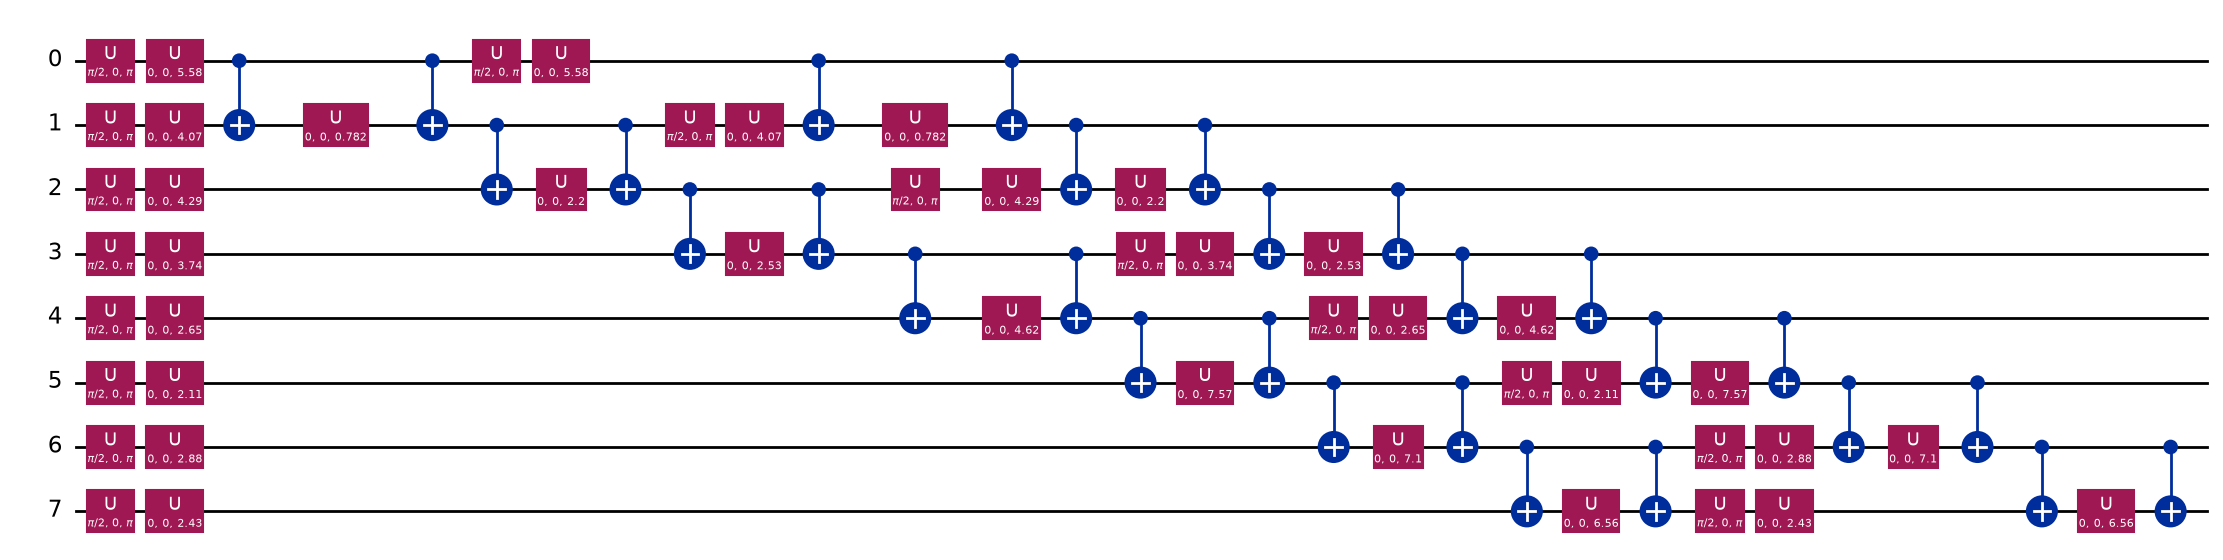

In [11]:
# ---- (a) quantum kernel: Qiskit ZZ feature map on 8 qubits, executed circuit with a data sample bound ----
fm = zz_feature_map(N_QUBITS, reps=KERNEL_REPS, entanglement=ENTANGLEMENT)
x_demo = S0.A_sub[0]
bound = fm.assign_parameters(list(x_demo))
dec = bound.decompose().decompose()
print(f"[Quantum kernel] qubits = {fm.num_qubits}, depth (decomposed to H/P/CX) = {dec.depth()}, data parameters = {fm.num_parameters}, "
      f"trainable parameters = 0 (the kernel is |<phi(a)|phi(b)>|^2 of two such circuits, evaluated exactly)")
display(dec.draw("mpl", fold=40))

In [12]:
# ---- equivalence of the notebook's kernel code with Qiskit's FidelityStatevectorKernel (assert) ----
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
ZS = bit_signs(N_QUBITS).T.numpy()                                  # (256, 8)  z_i = +-1 per basis state
ZZ_S = ZS[:, :-1] * ZS[:, 1:]                                        # (256, 7)  z_i z_{i+1}
WALSH = np.array([[(-1) ** bin(i & j).count("1") for j in range(2 ** N_QUBITS)] for i in range(2 ** N_QUBITS)]) / 2 ** (N_QUBITS / 2)

def zz_states(X, gamma=1.0):
    # exact |phi(x)> of zz_feature_map(n, reps=2, linear): H^n, diag(exp(i phi(x))), H^n, diag(exp(i phi(x)))
    x = gamma * X
    phi = x @ ZS.T + ((np.pi - x[:, :-1]) * (np.pi - x[:, 1:])) @ ZZ_S.T
    ph = np.exp(1j * phi)
    psi = ph / 2 ** (N_QUBITS / 2)
    for _ in range(KERNEL_REPS - 1):
        psi = (psi @ WALSH) * ph
    return psi

def fidelity_kernel(Xa, Xb, gamma=1.0):
    return np.abs(zz_states(Xa, gamma) @ zz_states(Xb, gamma).conj().T) ** 2

Xc = S0.A_sub[:8] * 0.5
K_mine = fidelity_kernel(Xc, Xc, 1.0)
K_qiskit = FidelityStatevectorKernel(feature_map=zz_feature_map(N_QUBITS, reps=KERNEL_REPS, entanglement=ENTANGLEMENT)).evaluate(Xc)
sv = [Statevector(zz_feature_map(N_QUBITS, reps=KERNEL_REPS, entanglement=ENTANGLEMENT).assign_parameters(list(x))) for x in Xc]
K_sv = np.array([[abs(a.inner(b)) ** 2 for b in sv] for a in sv])
assert np.allclose(K_mine, K_qiskit, atol=1e-10) and np.allclose(K_mine, K_sv, atol=1e-10)
print("assert OK: notebook kernel == Qiskit FidelityStatevectorKernel == Statevector overlaps (max abs diff %.2e)" % np.abs(K_mine - K_qiskit).max())

assert OK: notebook kernel == Qiskit FidelityStatevectorKernel == Statevector overlaps (max abs diff 1.89e-15)


[QNN-6L] qubits = 8, depth = 55, gates = 104, trainable circuit parameters = 48, classical head parameters = 0   (simulator == QNode: assert OK)


[QNN-8L] qubits = 8, depth = 73, gates = 136, trainable circuit parameters = 64, classical head parameters = 0   (simulator == QNode: assert OK)


[QNN-10L] qubits = 8, depth = 91, gates = 168, trainable circuit parameters = 80, classical head parameters = 0   (simulator == QNode: assert OK)


[HybridQNN-2L] qubits = 8, depth = 19, gates = 40, trainable circuit parameters = 16, classical head parameters = 18   (simulator == QNode: assert OK)


[HybridQNN-4L] qubits = 8, depth = 37, gates = 72, trainable circuit parameters = 32, classical head parameters = 18   (simulator == QNode: assert OK)


[HybridQNN-6L] qubits = 8, depth = 55, gates = 104, trainable circuit parameters = 48, classical head parameters = 18   (simulator == QNode: assert OK)


[HybridQNN-8L] qubits = 8, depth = 73, gates = 136, trainable circuit parameters = 64, classical head parameters = 18   (simulator == QNode: assert OK)


[HybridQNN-10L] qubits = 8, depth = 91, gates = 168, trainable circuit parameters = 80, classical head parameters = 18   (simulator == QNode: assert OK)


Matplotlib is building the font cache; this may take a moment.


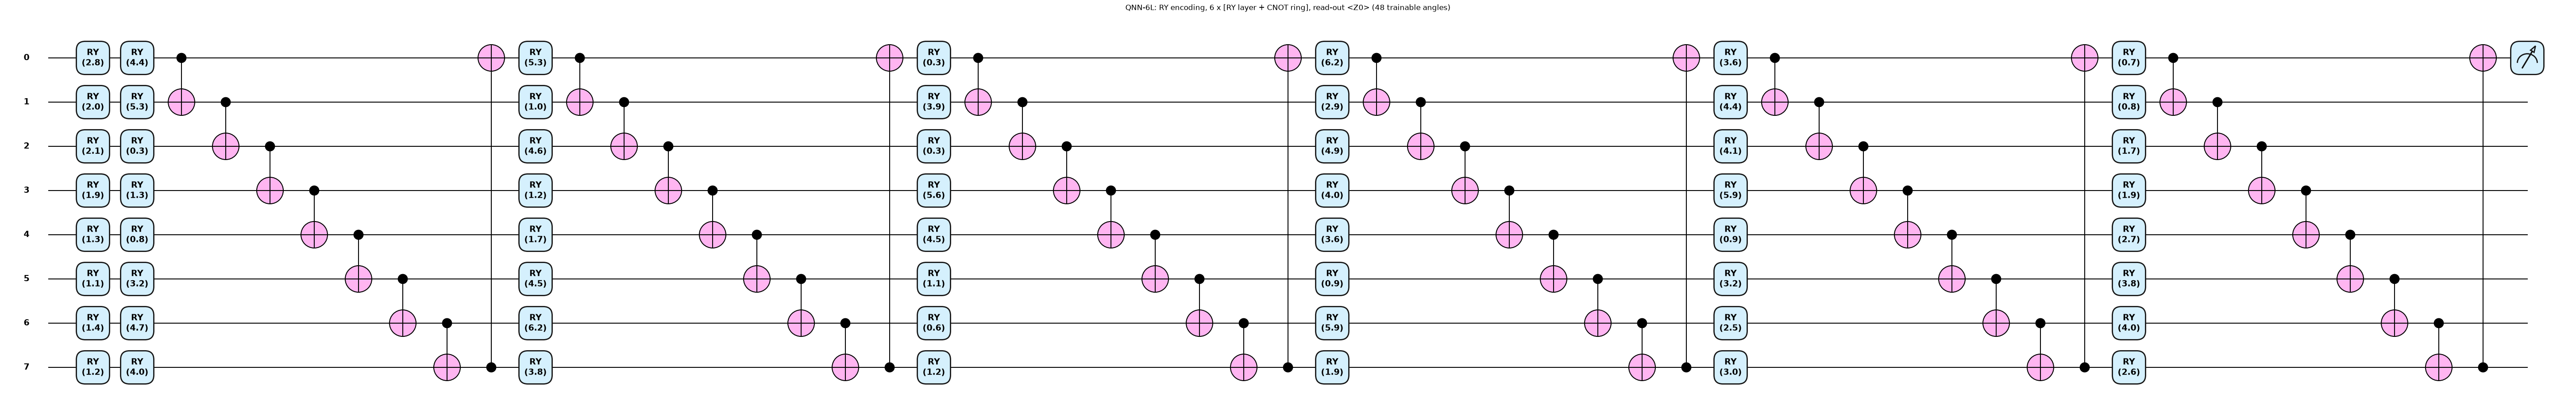

Matplotlib is building the font cache; this may take a moment.


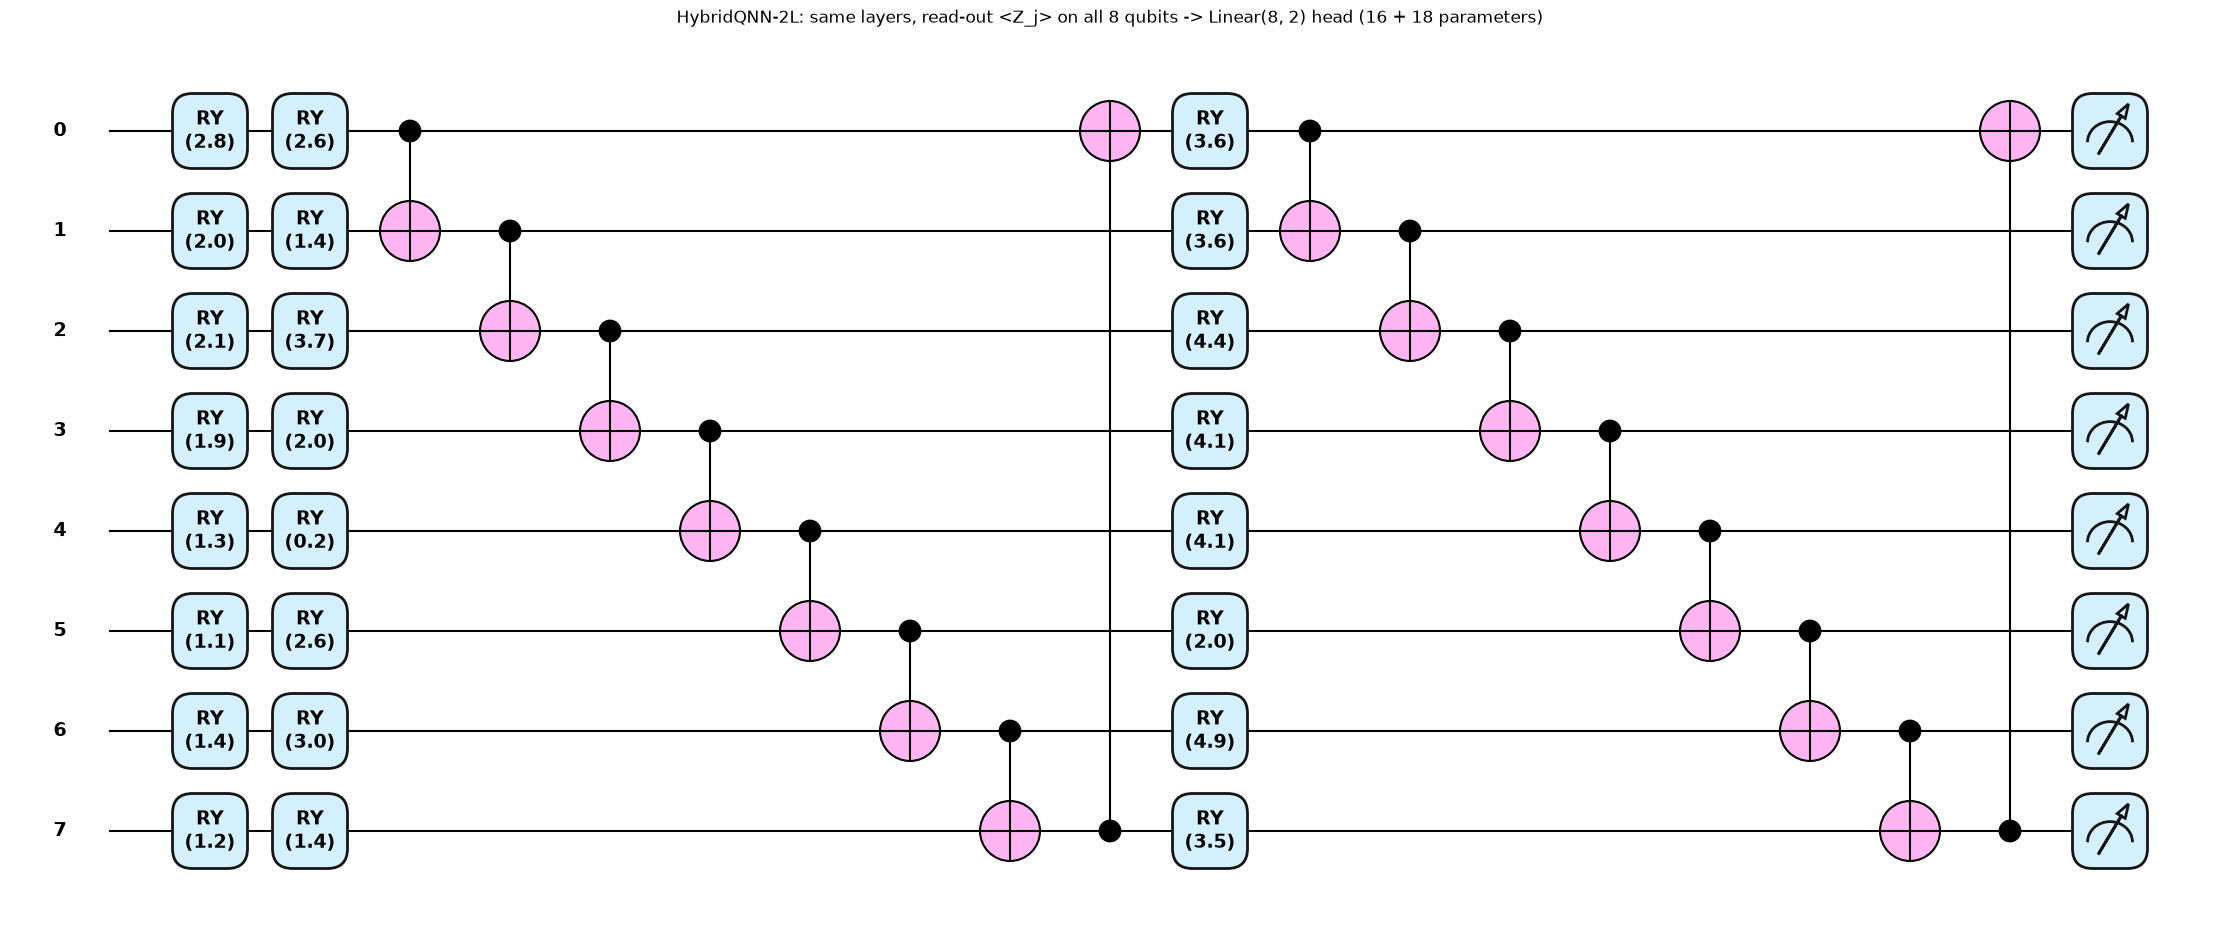

QNN-8L/10L and HybridQNN-4L/6L/8L/10L repeat the layer block (RY layer + CNOT ring) 8, 10, 4, 6, 8, 10 times; their depth and parameter counts are printed above.


In [13]:
# ---- (b) QNN / HybridQNN: PennyLane QNodes ----
def make_qnode(n, L, readout):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def circuit(x, theta):
        for j in range(n):
            qml.RY(x[j], wires=j)                                  # angle encoding
        for l in range(L):
            for j in range(n):
                qml.RY(theta[l, j], wires=j)                       # trainable rotation
            for j in range(n):
                qml.CNOT(wires=[j, (j + 1) % n])                   # entangling ring
        if readout == "single":
            return qml.expval(qml.PauliZ(0))                       # QNN read-out
        return [qml.expval(qml.PauliZ(j)) for j in range(n)]       # HybridQNN read-out (feeds the 18-parameter head)
    return circuit

rng_c = np.random.default_rng(SEED)
xs = S0.A_sub[:5]
for kind, Ls in (("single", [6, 8, 10]), ("all", [2, 4, 6, 8, 10])):
    for L in Ls:
        qn = make_qnode(8, L, kind); th = rng_c.uniform(0, 2 * np.pi, (L, 8))
        ref = np.array([np.atleast_1d(qn(x, th)) for x in xs])                   # PennyLane QNode
        zz = SIMS[8].zexp(SIMS[8].layers(SIMS[8].encode(torch.tensor(xs)), torch.tensor(th))).numpy()
        assert np.allclose(ref, zz[:, :ref.shape[1]], atol=1e-10)
        sp = qml.specs(qn)(xs[0], th)["resources"]
        print(f"[{'QNN' if kind == 'single' else 'HybridQNN'}-{L}L] qubits = 8, depth = {sp.depth}, gates = {sum(sp.gate_types.values())}, "
              f"trainable circuit parameters = {th.size}, classical head parameters = {0 if kind == 'single' else 18}   (simulator == QNode: assert OK)")

th6 = rng_c.uniform(0, 2 * np.pi, (6, 8))
fig, ax = qml.draw_mpl(make_qnode(8, 6, "single"), decimals=1, style="pennylane")(xs[0], th6)
ax.set_title("QNN-6L: RY encoding, 6 x [RY layer + CNOT ring], read-out <Z0> (48 trainable angles)"); plt.show()
th2 = rng_c.uniform(0, 2 * np.pi, (2, 8))
fig, ax = qml.draw_mpl(make_qnode(8, 2, "all"), decimals=1, style="pennylane")(xs[0], th2)
ax.set_title("HybridQNN-2L: same layers, read-out <Z_j> on all 8 qubits -> Linear(8, 2) head (16 + 18 parameters)"); plt.show()
print("QNN-8L/10L and HybridQNN-4L/6L/8L/10L repeat the layer block (RY layer + CNOT ring) 8, 10, 4, 6, 8, 10 times; "
      "their depth and parameter counts are printed above.")

[QT-NN (4,2)] qubits = 7, depth = 16, gates = 28, trainable circuit parameters = 14, generated classical weights = 66 (of 128 probabilities)   (simulator == QNode: assert OK)
[QT-NN (8,2)] qubits = 8, depth = 18, gates = 32, trainable circuit parameters = 16, generated classical weights = 162 (of 256 probabilities)   (simulator == QNode: assert OK)


[QT-NN (4,4)] qubits = 7, depth = 32, gates = 56, trainable circuit parameters = 28, generated classical weights = 66 (of 128 probabilities)   (simulator == QNode: assert OK)


[QT-NN (8,4)] qubits = 8, depth = 36, gates = 64, trainable circuit parameters = 32, generated classical weights = 162 (of 256 probabilities)   (simulator == QNode: assert OK)


[QT-NN (16,4)] qubits = 9, depth = 40, gates = 72, trainable circuit parameters = 36, generated classical weights = 450 (of 512 probabilities)   (simulator == QNode: assert OK)


Matplotlib is building the font cache; this may take a moment.


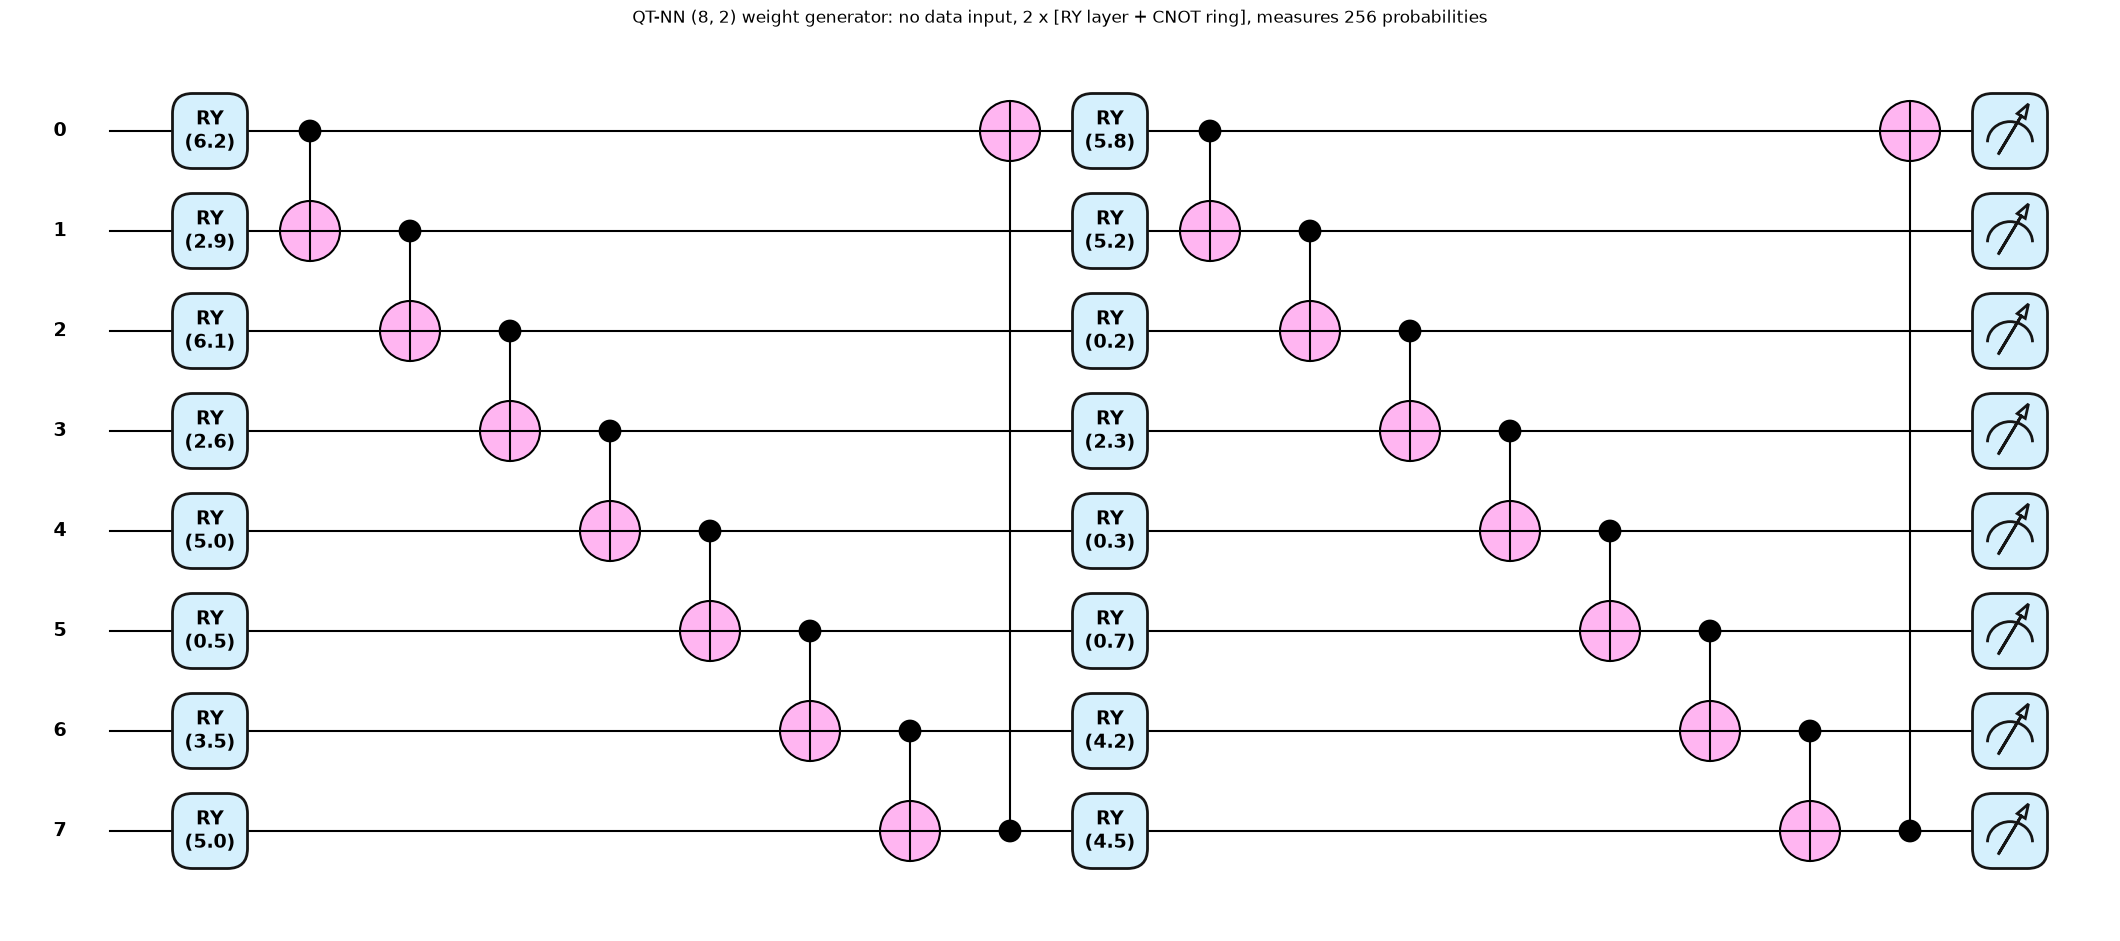

In [14]:
# ---- (c) QT-NN weight generator: PennyLane QNode returning the 2^n basis-state probabilities ----
def make_qt_qnode(n, L):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def circuit(theta):
        for l in range(L):
            for j in range(n):
                qml.RY(theta[l, j], wires=j)
            for j in range(n):
                qml.CNOT(wires=[j, (j + 1) % n])
        return qml.probs(wires=range(n))
    return circuit

QT_CONFIGS = [(4, 2), (8, 2), (4, 4), (8, 4), (16, 4)]       # (hidden width h, layers L) as in Table I
def qt_sizes(h):
    shapes = [(h, 8), (h,), (h, h), (h,), (2, h), (2,)]
    return shapes, sum(int(np.prod(s)) for s in shapes)
for h, L in QT_CONFIGS:
    shapes, size = qt_sizes(h); n = math.ceil(math.log2(size))
    th = rng_c.uniform(0, 2 * np.pi, (L, n)); qn = make_qt_qnode(n, L)
    assert np.allclose(qn(th), SIMS[n].probs(SIMS[n].layers(SIMS[n].zero(), torch.tensor(th)))[0].numpy(), atol=1e-12)
    sp = qml.specs(qn)(th)["resources"]
    print(f"[QT-NN ({h},{L})] qubits = {n}, depth = {sp.depth}, gates = {sum(sp.gate_types.values())}, trainable circuit parameters = {th.size}, "
          f"generated classical weights = {size} (of {2 ** n} probabilities)   (simulator == QNode: assert OK)")
th_demo = rng_c.uniform(0, 2 * np.pi, (2, 8))
fig, ax = qml.draw_mpl(make_qt_qnode(8, 2), decimals=1, style="pennylane")(th_demo)
ax.set_title("QT-NN (8, 2) weight generator: no data input, 2 x [RY layer + CNOT ring], measures 256 probabilities"); plt.show()

## 5. The quantum kernel SVM

The quantum kernel is $K(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2$ of two ZZ-feature-map states (Eq. 5), computed exactly with the
function that was asserted equal to Qiskit's `FidelityStatevectorKernel` above, and fed to `SVC(kernel="precomputed")`. The
angle scale $\gamma$ (the kernel bandwidth) and $C$ are chosen on an inner validation split of the training subset; the test
part is only touched once, at the end.

In [15]:
def run_kernel(S):
    t = time.time()
    itr, iva = inner_split(S.y_sub, S.seed)
    best = (-1, None)
    for g in BANDWIDTHS:
        st = zz_states(S.A_sub, g)
        K = np.abs(st @ st.conj().T) ** 2
        for C in C_GRID:
            m = SVC(kernel="precomputed", C=C).fit(K[np.ix_(itr, itr)], S.y_sub[itr])
            a = accuracy_score(S.y_sub[iva], m.predict(K[np.ix_(iva, itr)]))
            if a > best[0]: best = (a, (g, C))
    g, C = best[1]
    st = zz_states(S.A_sub, g); K = np.abs(st @ st.conj().T) ** 2
    m = SVC(kernel="precomputed", C=C).fit(K, S.y_sub)
    score = np.empty(len(S.A_te))
    for a in range(0, len(S.A_te), 4000):                         # test kernel in chunks
        Kt = np.abs(zz_states(S.A_te[a:a + 4000], g) @ st.conj().T) ** 2
        score[a:a + 4000] = m.decision_function(Kt)
    pred = (score > 0).astype(int)
    return record("Quantum kernel", S, pred, score, time.time() - t, extra=dict(hp=f"gamma={g}, C={C}, val acc={best[0]:.3f}"))

for S in SPLITS:
    r = run_kernel(S)
    print(f"seed {S.seed}: acc {r['acc']:.3f}  F1 {r['f1']:.3f}  spec {r['spec']:.3f}  sens {r['sens']:.3f}   [{r['hp']}]  {r['seconds']:.0f}s")

seed 42: acc 0.977  F1 0.986  spec 0.978  sens 0.977   [gamma=0.25, C=10.0, val acc=0.972]  58s


seed 43: acc 0.967  F1 0.978  spec 0.981  sens 0.963   [gamma=0.25, C=1.0, val acc=0.980]  39s


seed 44: acc 0.973  F1 0.983  spec 0.983  sens 0.971   [gamma=0.25, C=10.0, val acc=0.976]  38s


## 6. QNN, HybridQNN and QT-NN: variational training

All three are trained with Adam on mini-batches of the balanced training subset with cross-entropy, for `STEPS` steps, with
exact gradients obtained by back-propagating through the simulator (for noise-free simulation this equals the
parameter-shift gradient of Eq. 12 and 14). The weights at the last step are used (no early stopping, no test-set peeking).

* **QNN-$L$L**: $p(\text{attack})=(1-\langle Z_0\rangle)/2$; no classical parameters.
* **HybridQNN-$L$L**: the 8 expectations $\langle Z_j\rangle$ go through `Linear(8, 2)` (18 classical parameters).
* **QT-NN $(h, L)$**: the circuit has $n=\lceil\log_2(\text{weights})\rceil$ qubits; its probabilities $g(\theta)$ are cut into the
  weight / bias tensors of the MLP $8\to h\to h\to 2$ and each tensor is standardised and scaled by $1/\sqrt{\text{fan-in}}$
  (this is the paper's "normalisation / scaling" mapping $T$, Eq. 13). The classical weights are never trained directly.

In [16]:
class QNN(nn.Module):
    def __init__(self, L, seed):
        super().__init__(); g = torch.Generator().manual_seed(seed)
        self.sim = SIMS[8]; self.theta = nn.Parameter(torch.rand(L, 8, generator=g) * 2 * math.pi)
    def logits(self, A):
        z0 = self.sim.zexp(self.sim.layers(self.sim.encode(A), self.theta))[:, 0]
        p = torch.stack([(1 + z0) / 2, (1 - z0) / 2], -1).clamp_min(1e-7)
        return torch.log(p)                                           # softmax(log p) = p  ->  binary cross-entropy
    def counts(self): return self.theta.numel(), 0

class HybridQNN(nn.Module):
    def __init__(self, L, seed):
        super().__init__(); g = torch.Generator().manual_seed(seed)
        self.sim = SIMS[8]; self.theta = nn.Parameter(torch.rand(L, 8, generator=g) * 2 * math.pi)
        torch.manual_seed(seed); self.head = nn.Linear(8, 2)           # 8*2 + 2 = 18 classical parameters
    def logits(self, A):
        return self.head(self.sim.zexp(self.sim.layers(self.sim.encode(A), self.theta)))
    def counts(self): return self.theta.numel(), sum(p.numel() for p in self.head.parameters())

class QTNN(nn.Module):
    def __init__(self, h, L, seed):
        super().__init__(); g = torch.Generator().manual_seed(seed)
        self.shapes, self.size = qt_sizes(h); self.fan = [8, 8, h, h, h, h]
        self.n = math.ceil(math.log2(self.size)); self.sim = SIMS[self.n]
        self.theta = nn.Parameter(torch.rand(L, self.n, generator=g) * 2 * math.pi)
    def weights(self):
        g = self.sim.probs(self.sim.layers(self.sim.zero(), self.theta))[0]
        out, off = [], 0
        for s, fan in zip(self.shapes, self.fan):
            k = int(np.prod(s)); seg = g[off:off + k]; off += k
            w = (seg - seg.mean()) / (seg.std() + 1e-8) / math.sqrt(fan)     # CHOICE: T = standardise per tensor, scale 1/sqrt(fan-in)
            out.append(w.reshape(s))
        return out
    def logits(self, A):
        W1, b1, W2, b2, W3, b3 = self.weights()
        return F.relu(F.relu(A @ W1.T + b1) @ W2.T + b2) @ W3.T + b3
    def counts(self): return self.theta.numel(), self.size

def train(model, A, y, seed, steps=STEPS, batch=BATCH, lr=LR):
    A_t, y_t = torch.tensor(A), torch.tensor(y)
    g = torch.Generator().manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr); losses = []
    for s in range(steps):
        idx = torch.randint(0, len(A_t), (min(batch, len(A_t)),), generator=g)
        loss = F.cross_entropy(model.logits(A_t[idx]), y_t[idx])
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    return losses

@torch.no_grad()
def predict(model, A, chunk=4096):
    out = []
    for a in range(0, len(A), chunk):
        out.append(torch.softmax(model.logits(torch.tensor(A[a:a + chunk])), -1)[:, 1])
    p = torch.cat(out).numpy()
    return (p > 0.5).astype(int), p

def run_variational(S, name, model):
    t = time.time()
    losses = train(model, S.A_sub, S.y_sub, S.seed, steps=STEPS * (QT_STEPS_FACTOR if isinstance(model, QTNN) else 1))
    pred, p = predict(model, S.A_te)
    q, c = model.counts()
    if S.seed == SEED: CURVES[name] = losses
    return record(name, S, pred, p, time.time() - t, qparams=q, cparams=c)

MODEL_SPECS = ([(f"QNN-{L}L", lambda s, L=L: QNN(L, s)) for L in (6, 8, 10)] +
               [(f"HybridQNN-{L}L", lambda s, L=L: HybridQNN(L, s)) for L in (2, 4, 6, 8, 10)] +
               [(f"QT-NN ({h}, {L})", lambda s, h=h, L=L: QTNN(h, L, s)) for h, L in QT_CONFIGS])
for S in SPLITS:
    for name, ctor in MODEL_SPECS:
        r = run_variational(S, name, ctor(S.seed))
        print(f"seed {S.seed} {name:15s} q/c params {r['qparams']:3d}/{r['cparams']:3d}  acc {r['acc']:.3f}  F1 {r['f1']:.3f}  "
              f"spec {r['spec']:.3f}  sens {r['sens']:.3f}  {r['seconds']:.0f}s")

seed 42 QNN-6L          q/c params  48/  0  acc 0.879  F1 0.918  spec 0.938  sens 0.862  191s


seed 42 QNN-8L          q/c params  64/  0  acc 0.866  F1 0.908  spec 0.947  sens 0.844  138s


seed 42 QNN-10L         q/c params  80/  0  acc 0.898  F1 0.932  spec 0.935  sens 0.888  241s


seed 42 HybridQNN-2L    q/c params  16/ 18  acc 0.961  F1 0.975  spec 0.954  sens 0.963  59s


seed 42 HybridQNN-4L    q/c params  32/ 18  acc 0.965  F1 0.978  spec 0.958  sens 0.968  84s


...

seed 44 QT-NN (4, 2)    q/c params  14/ 66  acc 0.735  F1 0.801  spec 0.944  sens 0.678  46s


seed 44 QT-NN (8, 2)    q/c params  16/162  acc 0.877  F1 0.917  spec 0.935  sens 0.861  50s


seed 44 QT-NN (4, 4)    q/c params  28/ 66  acc 0.889  F1 0.926  spec 0.921  sens 0.880  48s


seed 44 QT-NN (8, 4)    q/c params  32/162  acc 0.924  F1 0.951  spec 0.877  sens 0.937  54s


seed 44 QT-NN (16, 4)   q/c params  36/450  acc 0.881  F1 0.920  spec 0.921  sens 0.870  63s


## 7. Table I re-computed, figures and the per-attack breakdown

In [17]:
res = pd.DataFrame(RESULTS)
ORDER = ["SVM (RBF, angles)", "Quantum kernel", "QNN-6L", "QNN-8L", "QNN-10L", "HybridQNN-2L", "HybridQNN-4L", "HybridQNN-6L",
         "HybridQNN-8L", "HybridQNN-10L", "QT-NN (4, 2)", "QT-NN (8, 2)", "QT-NN (4, 4)", "QT-NN (8, 4)", "QT-NN (16, 4)",
         "SVM (RBF, standardised z)", "Random forest", "MLP (32, 32)"]
agg = res.groupby("model")[["acc", "f1", "spec", "sens", "auc", "mcc", "macro_f1", "seconds"]].agg(["mean", "std"]).reindex(ORDER)
tab = pd.DataFrame({"qparams": res.groupby("model")["qparams"].first(), "cparams": res.groupby("model")["cparams"].first()}).reindex(ORDER)
for m in ["acc", "f1", "spec", "sens", "auc", "mcc"]:
    tab[m] = [f"{agg.loc[k, (m, 'mean')]:.3f}" + (f" +- {agg.loc[k, (m, 'std')]:.3f}" if N_SEEDS > 1 else "") for k in ORDER]
tab["sec"] = [f"{agg.loc[k, ('seconds', 'mean')]:.0f}" for k in ORDER]
print(f"Notebook Table I (binary IDS, attack = positive; mean over {N_SEEDS} seed(s); test part = {len(S0.y_te)} flows, natural mix)")
display(tab)

Notebook Table I (binary IDS, attack = positive; mean over 3 seed(s); test part = 24435 flows, natural mix)


,qparams,cparams,acc,f1,spec,sens,auc,mcc,sec
model,,,,,,,,,
"SVM (RBF, angles)",0,0,0.977 +- 0.004,0.985 +- 0.003,0.983 +- 0.005,0.975 +- 0.005,0.997 +- 0.000,0.934 +- 0.011,8
Quantum kernel,0,0,0.972 +- 0.006,0.982 +- 0.004,0.981 +- 0.003,0.970 +- 0.007,0.996 +- 0.001,0.922 +- 0.014,45
QNN-6L,48,0,0.877 +- 0.003,0.917 +- 0.002,0.941 +- 0.003,0.859 +- 0.004,0.974 +- 0.003,0.709 +- 0.005,157
QNN-8L,64,0,0.854 +- 0.010,0.899 +- 0.008,0.953 +- 0.011,0.827 +- 0.015,0.976 +- 0.005,0.676 +- 0.016,167
QNN-10L,80,0,0.890 +- 0.020,0.926 +- 0.015,0.943 +- 0.016,0.875 +- 0.029,0.978 +- 0.001,0.734 +- 0.030,210
HybridQNN-2L,16,18,0.953 +- 0.012,0.970 +- 0.008,0.959 +- 0.009,0.952 +- 0.018,0.992 +- 0.000,0.872 +- 0.028,66
HybridQNN-4L,32,18,0.955 +- 0.019,0.970 +- 0.013,0.961 +- 0.010,0.953 +- 0.027,0.993 +- 0.000,0.876 +- 0.043,87
HybridQNN-6L,48,18,0.948 +- 0.024,0.966 +- 0.017,0.961 +- 0.017,0.944 +- 0.035,0.993 +- 0.001,0.861 +- 0.052,143
HybridQNN-8L,64,18,0.949 +- 0.016,0.967 +- 0.011,0.969 +- 0.014,0.943 +- 0.025,0.993 +- 0.000,0.864 +- 0.034,184


Recall by true class (attack columns = per-attack sensitivity), seed 42


,Normal (=specificity),Blackhole,Wormhole,Sybil,Flooding
model,,,,,
"SVM (RBF, angles)",0.978,0.976,0.961,0.997,0.991
Quantum kernel,0.978,0.963,0.958,0.999,0.996
QNN-6L,0.938,0.660,0.873,0.985,0.967
QNN-8L,0.947,0.640,0.812,0.983,0.987
QNN-10L,0.935,0.730,0.875,0.985,0.996
HybridQNN-2L,0.954,0.967,0.901,0.995,1.000
HybridQNN-4L,0.958,0.957,0.930,0.992,1.000
HybridQNN-6L,0.960,0.955,0.890,0.986,1.000
HybridQNN-8L,0.962,0.955,0.902,0.992,1.000


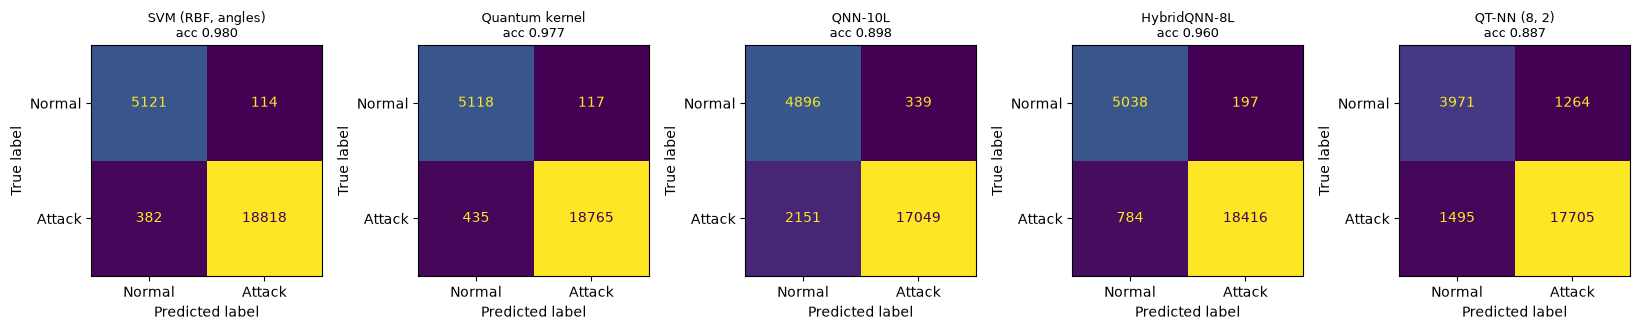

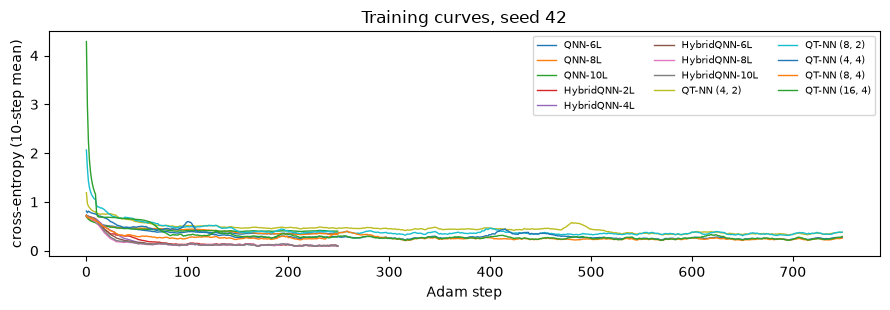

In [18]:
# per-attack breakdown (seed 0) and confusion matrices of key models
rec = res[res.seed == SEED].set_index("model").reindex(ORDER)[["rec_Normal", "rec_Blackhole", "rec_Wormhole", "rec_Sybil", "rec_Flooding"]]
rec.columns = ["Normal (=specificity)", "Blackhole", "Wormhole", "Sybil", "Flooding"]
print("Recall by true class (attack columns = per-attack sensitivity), seed", SEED)
display(rec.round(3))

key = ["SVM (RBF, angles)", "Quantum kernel", "QNN-10L", "HybridQNN-8L", "QT-NN (8, 2)"]
fig, axes = plt.subplots(1, len(key), figsize=(3.3 * len(key), 3.4))
for ax, k in zip(axes, key):
    r = res[(res.model == k) & (res.seed == SEED)].iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"{k}\nacc {r.acc:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
for k, v in CURVES.items():
    sm = pd.Series(v).rolling(10, min_periods=1).mean()
    ax.plot(sm.values, label=k, lw=1)
ax.set_xlabel("Adam step"); ax.set_ylabel("cross-entropy (10-step mean)"); ax.set_title("Training curves, seed %d" % SEED)
ax.legend(ncol=3, fontsize=7); plt.tight_layout(); plt.show()

## 8. Side by side with the paper and a verdict per claim

The paper's Table I is typed in below. A row is **reproduced** when accuracy is within 0.02 and F1 within 0.02 of the paper
(mean over seeds); otherwise **exceeded** (we are better by more than the tolerance) or **not reached**. Specificity and
sensitivity gaps are shown in the table. Aggregate claims quoted in the paper's text are tested after the table.

,p_acc,acc,d_acc,p_f1,f1,d_f1,p_spec,spec,d_spec,p_sens,sens,d_sens,"verdict (acc, F1)",spec/sens within 0.05
model,,,,,,,,,,,,,,
"SVM (RBF, angles)",0.924,0.977,0.053,0.951,0.985,0.034,0.836,0.983,0.147,0.947,0.975,0.028,exceeded,no
Quantum kernel,0.926,0.972,0.046,0.956,0.982,0.026,0.728,0.981,0.253,0.981,0.970,-0.011,exceeded,no
QNN-6L,0.799,0.877,0.078,0.887,0.917,0.030,0.066,0.941,0.875,0.999,0.859,-0.140,exceeded,no
QNN-8L,0.793,0.854,0.061,0.883,0.899,0.016,0.040,0.953,0.913,0.998,0.827,-0.171,exceeded,no
QNN-10L,0.824,0.890,0.066,0.898,0.926,0.028,0.234,0.943,0.709,0.986,0.875,-0.111,exceeded,no
HybridQNN-2L,0.926,0.953,0.027,0.952,0.970,0.018,0.896,0.959,0.063,0.934,0.952,0.018,exceeded,no
HybridQNN-4L,0.933,0.955,0.022,0.957,0.970,0.013,0.861,0.961,0.100,0.953,0.953,-0.000,exceeded,no
HybridQNN-6L,0.930,0.948,0.018,0.954,0.966,0.012,0.904,0.961,0.057,0.937,0.944,0.007,reproduced,no
HybridQNN-8L,0.948,0.949,0.001,0.967,0.967,-0.000,0.838,0.969,0.131,0.972,0.943,-0.029,reproduced,no


{'exceeded': 9, 'reproduced': 4, 'not reached': 2}


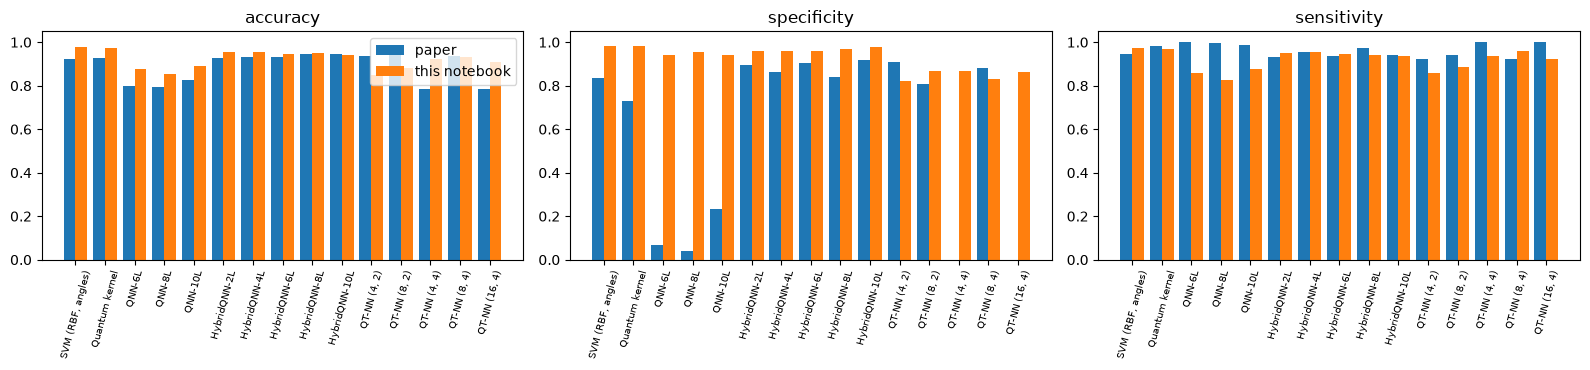

In [19]:
PAPER = pd.DataFrame([
    ("SVM (RBF, angles)",  0.924, 0.951, 0.836, 0.947), ("Quantum kernel", 0.926, 0.956, 0.728, 0.981),
    ("QNN-6L", 0.799, 0.887, 0.066, 0.999), ("QNN-8L", 0.793, 0.883, 0.040, 0.998), ("QNN-10L", 0.824, 0.898, 0.234, 0.986),
    ("HybridQNN-2L", 0.926, 0.952, 0.896, 0.934), ("HybridQNN-4L", 0.933, 0.957, 0.861, 0.953),
    ("HybridQNN-6L", 0.930, 0.954, 0.904, 0.937), ("HybridQNN-8L", 0.948, 0.967, 0.838, 0.972),
    ("HybridQNN-10L", 0.944, 0.965, 0.920, 0.942), ("QT-NN (4, 2)", 0.937, 0.959, 0.908, 0.923),
    ("QT-NN (8, 2)", 0.939, 0.960, 0.808, 0.940), ("QT-NN (4, 4)", 0.786, 0.879, 0.000, 1.000),
    ("QT-NN (8, 4)", 0.938, 0.959, 0.881, 0.925), ("QT-NN (16, 4)", 0.786, 0.879, 0.000, 1.000),
], columns=["model", "p_acc", "p_f1", "p_spec", "p_sens"]).set_index("model")

mean = res.groupby("model")[["acc", "f1", "spec", "sens"]].mean()
cmp_ = PAPER.join(mean)
for m in ["acc", "f1", "spec", "sens"]:
    cmp_["d_" + m] = (cmp_[m] - cmp_["p_" + m]).round(3)
def verdict(r):
    if abs(r.d_acc) <= TOL_ACC and abs(r.d_f1) <= TOL_F1: return "reproduced"
    return "exceeded" if (r.d_acc > TOL_ACC) else "not reached"
cmp_["verdict (acc, F1)"] = cmp_.apply(verdict, axis=1)
cmp_["spec/sens within 0.05"] = [("yes" if (abs(r.d_spec) <= TOL_SS and abs(r.d_sens) <= TOL_SS) else "no") for r in cmp_.itertuples()]
show = cmp_[["p_acc", "acc", "d_acc", "p_f1", "f1", "d_f1", "p_spec", "spec", "d_spec", "p_sens", "sens", "d_sens", "verdict (acc, F1)", "spec/sens within 0.05"]]
display(show.round(3))
print(cmp_["verdict (acc, F1)"].value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=False)
x = np.arange(len(cmp_)); w = 0.4
for ax, (m, t) in zip(axes, [("acc", "accuracy"), ("spec", "specificity"), ("sens", "sensitivity")]):
    ax.bar(x - w / 2, cmp_["p_" + m], w, label="paper"); ax.bar(x + w / 2, cmp_[m], w, label="this notebook")
    ax.set_xticks(x); ax.set_xticklabels(cmp_.index, rotation=75, fontsize=7); ax.set_title(t); ax.set_ylim(0, 1.05)
axes[0].legend(); plt.tight_layout(); plt.show()

In [20]:
# ---- aggregate claims of the paper's text, checked against our means ----
g = lambda k, m: float(mean.loc[k, m])
claims = []
def claim(text, ok, detail):
    claims.append((text, "reproduced" if ok is True else ("not reached" if ok is False else "cannot be checked"), detail))

claim("Quantum kernel and classical SVM are close (accuracy within 0.01; paper 0.926 vs 0.924)",
      abs(g("Quantum kernel", "acc") - g("SVM (RBF, angles)", "acc")) <= 0.01,
      f"kernel {g('Quantum kernel','acc'):.3f} vs SVM {g('SVM (RBF, angles)','acc'):.3f}")
claim("Quantum kernel has the lower specificity of the two (0.728 vs 0.836)",
      g("Quantum kernel", "spec") < g("SVM (RBF, angles)", "spec"),
      f"kernel {g('Quantum kernel','spec'):.3f} vs SVM {g('SVM (RBF, angles)','spec'):.3f}")
deep = ["QNN-6L", "QNN-8L", "QNN-10L"]
claim("Deep pure QNNs have sensitivity near 1 but specificity collapsing to 0.04-0.23",
      all(g(k, "sens") > 0.95 and g(k, "spec") < 0.30 for k in deep),
      ", ".join(f"{k}: sens {g(k,'sens'):.2f} / spec {g(k,'spec'):.2f}" for k in deep))
claim("Pure QNNs are about ten accuracy points below the classical models",
      all(g(k, "acc") <= g("SVM (RBF, angles)", "acc") - 0.07 for k in deep),
      ", ".join(f"{k}: {g(k,'acc'):.3f}" for k in deep) + f" vs SVM {g('SVM (RBF, angles)','acc'):.3f}")
hyb = [f"HybridQNN-{L}L" for L in (2, 4, 6, 8, 10)]
claim("Hybrid QNNs beat the pure QNNs and reach 0.93-0.95 accuracy",
      all(g(k, "acc") >= 0.91 for k in hyb) and min(g(k, "acc") for k in hyb) > max(g(k, "acc") for k in deep),
      ", ".join(f"{k}: {g(k,'acc'):.3f}" for k in hyb))
claim("The 8-layer HybridQNN is the best model of Table I (acc 0.948)",
      max(PAPER.index, key=lambda k: g(k, "acc")) == "HybridQNN-8L",
      "best here: " + max(PAPER.index, key=lambda k: g(k, "acc")) + f" ({max(g(k,'acc') for k in PAPER.index):.3f}); HybridQNN-8L {g('HybridQNN-8L','acc'):.3f}")
claim("Hybrid QNNs beat the classical SVM by about 0.01-0.02 accuracy",
      g("HybridQNN-8L", "acc") - g("SVM (RBF, angles)", "acc") >= 0.01,
      f"HybridQNN-8L - SVM = {g('HybridQNN-8L','acc') - g('SVM (RBF, angles)','acc'):+.3f}")
good = ["QT-NN (4, 2)", "QT-NN (8, 2)", "QT-NN (8, 4)"]
claim("QT-NN (4,2), (8,2), (8,4) reach about 0.94 accuracy with specificity above 0.80",
      all(abs(g(k, "acc") - 0.94) <= 0.03 and g(k, "spec") > 0.80 for k in good),
      ", ".join(f"{k}: acc {g(k,'acc'):.3f} / spec {g(k,'spec'):.2f}" for k in good))
bad = ["QT-NN (4, 4)", "QT-NN (16, 4)"]
claim("QT-NN (4,4) and (16,4) collapse to 'attack for every flow' (acc 0.786, spec 0)",
      all(g(k, "spec") < 0.05 for k in bad),
      ", ".join(f"{k}: acc {g(k,'acc'):.3f} / spec {g(k,'spec'):.2f}" for k in bad))
claim("CNNs dominate when abundant data offset their parameter count (abstract)", None, "no CNN result is reported in the paper's Table I; not tested")
claim("Results hold under shot noise / noise models, circuit depth and qubit-count studies (abstract)", None, "only the noise-free Table I is reported; not tested here")
cl = pd.DataFrame(claims, columns=["claim of the paper", "verdict", "notebook evidence"])
pd.set_option("display.max_colwidth", 140)
display(cl)
print(cl["verdict"].value_counts().to_dict())

,claim of the paper,verdict,notebook evidence
0,Quantum kernel and classical SVM are close (accuracy within 0.01; paper 0.926 vs 0.924),reproduced,kernel 0.972 vs SVM 0.977
1,Quantum kernel has the lower specificity of the two (0.728 vs 0.836),reproduced,kernel 0.981 vs SVM 0.983
2,Deep pure QNNs have sensitivity near 1 but specificity collapsing to 0.04-0.23,not reached,"QNN-6L: sens 0.86 / spec 0.94, QNN-8L: sens 0.83 / spec 0.95, QNN-10L: sens 0.88 / spec 0.94"
3,Pure QNNs are about ten accuracy points below the classical models,reproduced,"QNN-6L: 0.877, QNN-8L: 0.854, QNN-10L: 0.890 vs SVM 0.977"
4,Hybrid QNNs beat the pure QNNs and reach 0.93-0.95 accuracy,reproduced,"HybridQNN-2L: 0.953, HybridQNN-4L: 0.955, HybridQNN-6L: 0.948, HybridQNN-8L: 0.949, HybridQNN-10L: 0.943"
5,The 8-layer HybridQNN is the best model of Table I (acc 0.948),not reached,"best here: SVM (RBF, angles) (0.977); HybridQNN-8L 0.949"
6,Hybrid QNNs beat the classical SVM by about 0.01-0.02 accuracy,not reached,HybridQNN-8L - SVM = -0.028
7,"QT-NN (4,2), (8,2), (8,4) reach about 0.94 accuracy with specificity above 0.80",not reached,"QT-NN (4, 2): acc 0.850 / spec 0.82, QT-NN (8, 2): acc 0.883 / spec 0.87, QT-NN (8, 4): acc 0.931 / spec 0.83"
8,"QT-NN (4,4) and (16,4) collapse to 'attack for every flow' (acc 0.786, spec 0)",not reached,"QT-NN (4, 4): acc 0.923 / spec 0.87, QT-NN (16, 4): acc 0.910 / spec 0.86"
9,CNNs dominate when abundant data offset their parameter count (abstract),cannot be checked,no CNN result is reported in the paper's Table I; not tested


{'not reached': 5, 'reproduced': 4, 'cannot be checked': 2}


## Reading the paper critically

* **The test set decides what the numbers mean.** About 79 % of the test flows are attacks, so a model that always says
  "attack" scores accuracy 0.786 and sensitivity 1.0. The paper's three QNN rows and two QT-NN rows sit on or within 0.04 of
  that floor, and its "best" HybridQNN beats the SVM by 0.02 accuracy while its specificity is the same as the SVM's.
  Accuracy and F1 hide this; specificity, MCC and the per-attack recalls above do not.
* **The classical baseline is the weak point of the comparison.** With the same eight (proxy) features, an RBF SVM with a small
  validation grid reaches about 0.977 accuracy here, a random forest 0.984 and a small MLP 0.969, all above every quantum model
  we trained and well above the paper's SVM (0.924, specificity 0.836). The paper does not state the SVM's kernel or its
  hyper-parameters, so "the quantum kernel matches / the hybrid beats the classical SVM" depends on an SVM that is probably
  untuned. Our quantum-kernel SVM equals our classical SVM within the seed noise (0.972 vs 0.977), the same qualitative result as the
  paper's 0.926 vs 0.924, but at a much higher accuracy level for both.
* **Differences of one or two points are inside the noise.** The paper gives one number per model without seeds. Over three
  splits / initialisations the HybridQNN rows differ from each other by far less than their standard deviations (0.012-0.024), so the
  ranking of 2, 4, 6, 8 and 10 layers (and "8 layers is best") cannot be read off a single run.
* **The "hybrid" gain comes with the classical head.** The pure QNN (same circuit, no head, read-out of one qubit) is 5-10
  accuracy points below the HybridQNN here, the same direction as in the paper (QNN about 0.80-0.82 vs hybrid 0.93-0.95). We do **not**
  see the paper's "specificity collapse" (0.04-0.23): trained on a balanced subset with cross-entropy our QNNs keep specificity
  around 0.94-0.95. A specificity near zero is what a constant "attack" output (or training on the imbalanced mix) produces,
  so the paper's collapse looks more like an optimisation / protocol artefact than a property of deep circuits.
* **QT-NN.** Our QT-NN reach 0.85-0.93 accuracy and vary strongly with the seed (standard deviation up to 0.10); the paper's two
  all-attack collapses ((4,4) and (16,4)) do not occur here, and our best QT-NN is below the HybridQNN. The mapping $T$ from
  probabilities to weights is not specified in the paper and its scaling matters a lot.
* **Features.** The paper's three most "interpretable" features need packet timestamps and directional byte counts. The public
  CSV has neither, so the notebook uses proxies; the exact accuracies (and the ranking) may change with the real features.
* **Simulation only.** The abstract mentions noise models and shot noise, but Table I is noise-free and no hardware is used.
* **The data are simulated** (NS-3 with idealised attacks) and easy: tree ensembles reach 0.98-0.99 on them. Strong results
  on UAVIDS-2025 do not show robustness on real swarms.

## Exercises

1. Train the classical MLP and the HybridQNN-8L with the **same number of trainable parameters** (e.g. an MLP with 18 + 64 weights)
   and compare them over 5 seeds. Does the hybrid model still win?
2. Replace the three proxy features by other columns of the CSV (for example `PacketDropRate`, `AverageHopCount`, `Throughput/Kbps`)
   and re-run the table. Which models are sensitive to the feature choice?
3. Change the QNN read-out from $\langle Z_0\rangle$ to the parity $\langle Z_0Z_1\cdots Z_7\rangle$ or to a mean of all $\langle Z_j\rangle$
   and see whether the "specificity collapse" of the deep QNNs remains.
4. Re-train with a test-matching (imbalanced) training set and with class weights; how do accuracy, specificity and MCC move?
5. Add shot noise: estimate the QNN expectations with 1,000 / 100 shots (`np.random.binomial`) and check how fast accuracy degrades.